# Why was data drift reported?

This notebook explains the result of `detect_drift.py` on `reference_data.tsv` (what the model was trained on) and `current_data.tsv` (the new data).

**Short answer:** the house **size** (`sqft`) and **bedroom count** (`bedrooms`) of the new houses are distributed differently from the reference houses. `age` is unchanged. The KS test flags `sqft` and `bedrooms`, so the pipeline retrains.

Place this notebook in the repo root, next to the two `.tsv` files.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REF_COLOR, CUR_COLOR = "#4C78A8", "#E4572E"

reference = pd.read_csv("reference_data.tsv", sep="\t")
current = pd.read_csv("current_data.tsv", sep="\t")
print(reference.shape, current.shape)
reference.head()

(1000, 4) (1000, 4)


,sqft,bedrooms,age,price
0,1299,2,29,128882
1,1172,2,7,129547
2,1329,3,10,172096
3,1504,3,19,144555
4,1153,1,27,149819


## 1. What the test does

The two-sample **Kolmogorov-Smirnov (KS) test** asks: *could these two samples have come from the same distribution?*

- It builds the cumulative distribution (ECDF) of each sample and takes the **largest vertical gap** between them. That gap is the **KS statistic** (0 = identical, 1 = completely different).
- The **p-value** is the probability of seeing a gap this large if both samples really came from the same distribution.
- **Low p-value (< 0.05) = the distributions differ = drift.** A high p-value means no evidence of drift.

## 2. The result the pipeline saw

In [2]:
COLUMNS = ["sqft", "bedrooms", "age"]
THRESHOLD = 0.05

rows = []
for col in COLUMNS:
    stat, p = ks_2samp(reference[col], current[col])
    rows.append({
        "column": col,
        "ref mean": reference[col].mean(),
        "new mean": current[col].mean(),
        "mean shift %": 100 * (current[col].mean() / reference[col].mean() - 1),
        "KS statistic": stat,
        "p-value": p,
        "drift?": "YES" if p < THRESHOLD else "no",
    })
results = pd.DataFrame(rows).set_index("column")
results.style.format({"ref mean": "{:.1f}", "new mean": "{:.1f}", "mean shift %": "{:+.1f}%",
                      "KS statistic": "{:.3f}", "p-value": "{:.2e}"})

,ref mean,new mean,mean shift %,KS statistic,p-value,drift?
column,,,,,,
sqft,1203.4,1350.8,+12.2%,0.285,3.55e-36,YES
bedrooms,2.5,2.8,+11.9%,0.152,1.71e-10,YES
age,14.4,14.4,-0.4%,0.022,9.69e-01,no


`sqft` and `bedrooms` have p-values far below 0.05, so the script exits with drift. `age` has a p-value near 0.97, so it is the same in both datasets. **One drifted column is enough** for `detect_drift.py` to report drift.

Now let's see *what* changed.

## 3. `sqft`: new houses are bigger

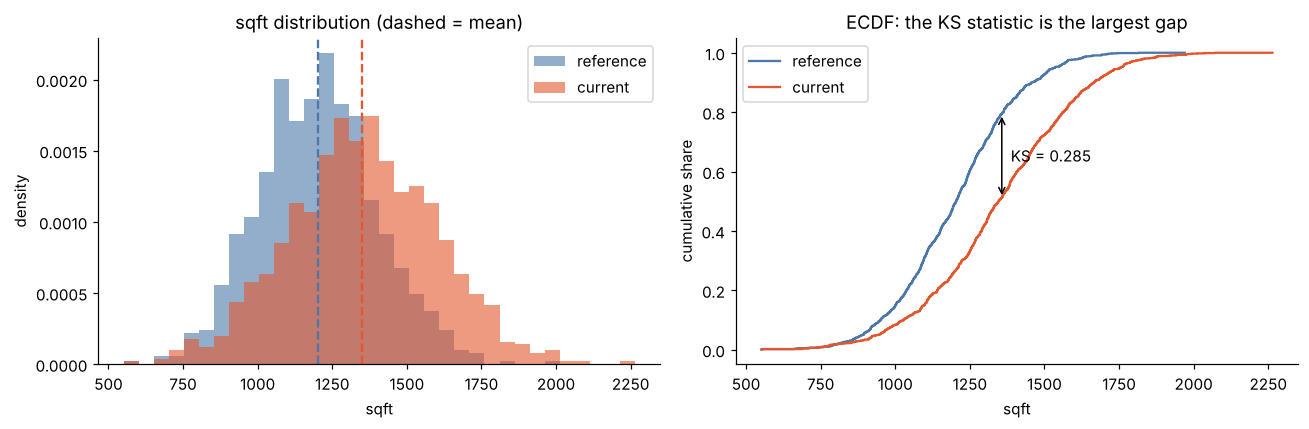

       reference  current
count     1000.0   1000.0
mean      1203.0   1351.0
std        196.0    247.0
min        551.0    553.0
25%       1070.0   1190.0
50%       1204.0   1346.0
75%       1329.0   1524.0
max       1970.0   2264.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(min(reference.sqft.min(), current.sqft.min()), max(reference.sqft.max(), current.sqft.max()), 35)
axes[0].hist(reference.sqft, bins=bins, alpha=0.6, color=REF_COLOR, label="reference", density=True)
axes[0].hist(current.sqft, bins=bins, alpha=0.6, color=CUR_COLOR, label="current", density=True)
axes[0].axvline(reference.sqft.mean(), color=REF_COLOR, ls="--")
axes[0].axvline(current.sqft.mean(), color=CUR_COLOR, ls="--")
axes[0].set(title="sqft distribution (dashed = mean)", xlabel="sqft", ylabel="density")
axes[0].legend()

# ECDFs: the KS statistic is the biggest vertical gap between these two curves
def ecdf(x):
    x = np.sort(x); return x, np.arange(1, len(x) + 1) / len(x)

xr, yr = ecdf(reference.sqft); xc, yc = ecdf(current.sqft)
axes[1].step(xr, yr, color=REF_COLOR, label="reference")
axes[1].step(xc, yc, color=CUR_COLOR, label="current")

grid = np.sort(np.concatenate([xr, xc]))
gap = np.abs(np.searchsorted(xr, grid, side="right") / len(xr) - np.searchsorted(xc, grid, side="right") / len(xc))
g = grid[gap.argmax()]
y1 = np.searchsorted(xr, g, side="right") / len(xr); y2 = np.searchsorted(xc, g, side="right") / len(xc)
axes[1].annotate("", xy=(g, y2), xytext=(g, y1), arrowprops=dict(arrowstyle="<->", color="black"))
axes[1].text(g + 30, (y1 + y2) / 2, f"KS = {gap.max():.3f}", va="center")
axes[1].set(title="ECDF: the KS statistic is the largest gap", xlabel="sqft", ylabel="cumulative share")
axes[1].legend()
plt.tight_layout(); plt.show()

print(reference.sqft.describe().round(0).to_frame("reference").join(current.sqft.describe().round(0).to_frame("current")))

The whole `sqft` distribution has moved to the right, with a higher mean and a wider spread. At about 1,350 sqft, the share of houses at or below that size is roughly 29 percentage points higher in the reference data than in the new data (that gap is the KS statistic). With 1,000 rows in each sample, a gap this large is essentially impossible by chance.

## 4. `bedrooms`: more 3 and 4-bedroom homes

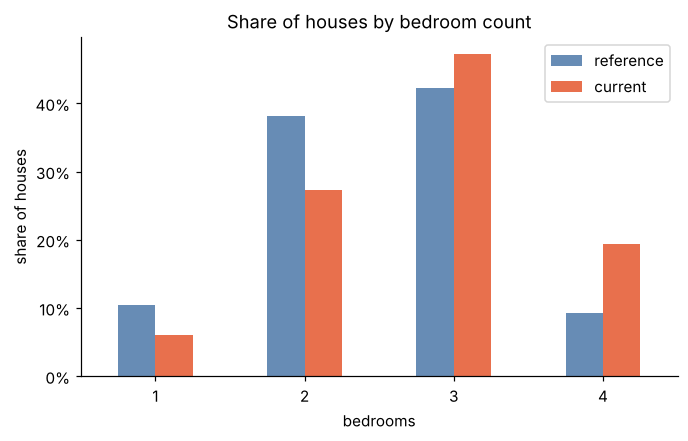

,reference,current,change
bedrooms,,,
1,10.4,6.0,-4.4
2,38.1,27.3,-10.8
3,42.3,47.3,5.0
4,9.2,19.4,10.2


In [4]:
counts = pd.DataFrame({
    "reference": reference.bedrooms.value_counts(normalize=True).sort_index(),
    "current": current.bedrooms.value_counts(normalize=True).sort_index(),
}).fillna(0)

ax = counts.plot.bar(color=[REF_COLOR, CUR_COLOR], alpha=0.85, figsize=(7, 4), rot=0)
ax.set(title="Share of houses by bedroom count", xlabel="bedrooms", ylabel="share of houses")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()
(counts * 100).round(1).assign(change=lambda d: (d.current - d.reference).round(1)).rename_axis("bedrooms")

The mix shifted toward larger homes: 4-bedroom houses roughly doubled (about 9% to 19%) while 1 and 2-bedroom houses became less common.

> **Note:** `bedrooms` only takes four values (1 to 4). The KS test is designed for continuous data and is only approximate for discrete values like this. A chi-square test on the counts is the more appropriate check, and it agrees here (see the cell below).

In [5]:
from scipy.stats import chi2_contingency
table = pd.concat([reference.bedrooms.value_counts(), current.bedrooms.value_counts()], axis=1).fillna(0).sort_index()
chi2, p, dof, _ = chi2_contingency(table.values)
print(f"Chi-square test on bedroom counts: chi2 = {chi2:.1f}, p-value = {p:.2e}  (drift confirmed)")

Chi-square test on bedroom counts: chi2 = 68.8, p-value = 7.68e-15  (drift confirmed)


## 5. `age`: no change (the control)

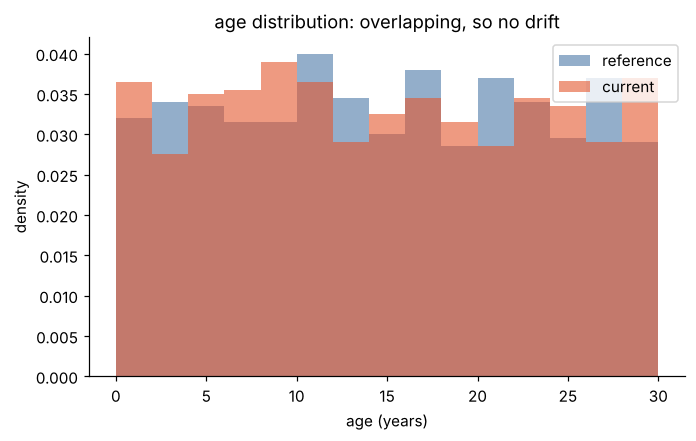

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(0, 31, 2)
ax.hist(reference.age, bins=bins, alpha=0.6, color=REF_COLOR, label="reference", density=True)
ax.hist(current.age, bins=bins, alpha=0.6, color=CUR_COLOR, label="current", density=True)
ax.set(title="age distribution: overlapping, so no drift", xlabel="age (years)", ylabel="density")
ax.legend(); plt.show()

The two histograms sit on top of each other, which is what a healthy, non-drifting feature looks like. Keeping an unchanged column in the check shows the test is not flagging everything.

## 6. Does the drift matter for the model?

Drift in the inputs only matters if it hurts predictions. The check below trains a model on the reference data (like the current model) and scores it on both datasets.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

FEATURES = ["sqft", "bedrooms", "age"]

def split(df):
    return train_test_split(df[FEATURES], df["price"], test_size=0.2, random_state=42)

Xr_tr, Xr_te, yr_tr, yr_te = split(reference)
Xc_tr, Xc_te, yc_tr, yc_te = split(current)

old_model = LinearRegression().fit(Xr_tr, yr_tr)   # trained on reference data
new_model = LinearRegression().fit(Xc_tr, yc_tr)   # what retrain_model.py does

summary = pd.DataFrame({
    "old model on reference test": [mean_absolute_error(yr_te, old_model.predict(Xr_te)), r2_score(yr_te, old_model.predict(Xr_te))],
    "old model on NEW test":       [mean_absolute_error(yc_te, old_model.predict(Xc_te)), r2_score(yc_te, old_model.predict(Xc_te))],
    "retrained model on NEW test": [mean_absolute_error(yc_te, new_model.predict(Xc_te)), r2_score(yc_te, new_model.predict(Xc_te))],
}, index=["MAE", "R2"]).T
summary.style.format({"MAE": "{:,.0f}", "R2": "{:.3f}"})

,MAE,R2
old model on reference test,"19,824",-0.029
old model on NEW test,"26,069",-0.098
retrained model on NEW test,"24,798",-0.010


In [8]:
print("Price coefficients (per unit of each feature)")
print(pd.DataFrame({"old model": old_model.coef_, "retrained": new_model.coef_}, index=FEATURES).round(1))

Price coefficients (per unit of each feature)
          old model  retrained
sqft           -0.8       12.6
bedrooms     1659.2       48.3
age           -43.2      -34.6


**Read this table carefully.** R2 is close to zero for every row, and the coefficients above are tiny or erratic. In this dataset `price` is almost uncorrelated with `sqft`, `bedrooms` and `age`, so the linear model explains almost none of the price variation both before and after retraining. Retraining changes the coefficients, but it does not make the model useful. This looks like synthetic data where each column was generated independently, which is fine for demonstrating the pipeline, but do not read the MAE numbers as real model quality.

## 7. Takeaways

- Drift was reported because **`sqft` and `bedrooms` in the new data differ significantly from the reference data** (p-values near zero). New houses are larger with more bedrooms. `age` did not change.
- The script flags drift if **any** monitored column has p < 0.05, so two columns were enough.
- With 1,000 rows per sample, the KS test is very sensitive and picks up even small shifts. In production, also look at the **size** of the shift (the KS statistic or mean change), not just the p-value, to avoid retraining on tiny differences.
- Section 6 shows that on this data the model has almost no predictive power (R2 near 0) before or after retraining, because `price` is nearly independent of the inputs. The demo proves the drift-and-retrain pipeline works, not that retraining improves accuracy. On real data, compare model metrics before and after, and retrain only if the drift hurts performance.